In [1]:
%pip install langgraph langchain-core

  Using cached langgraph-1.2.11-py3-none-any.whl.metadata (4.9 kB)
  Using cached langchain_core-1.6.1-py3-none-any.whl.metadata (4.8 kB)
  Using cached langgraph_checkpoint-4.2.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached langgraph_prebuilt-1.1.0-py3-none-any.whl.metadata (5.2 kB)
  Using cached langgraph_sdk-0.4.4-py3-none-any.whl.metadata (5.1 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached jsonpatch-1.33-py2.py3-none-any.whl.metadata (3.0 kB)
  Using cached langchain_protocol-0.0.19-py3-none-any.whl.metadata (2.4 kB)
  Using cached langsmith-0.11.2-py3-none-any.whl.metadata (22 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
Using cached langgraph-1.2.11-py3-none-any.whl (248 kB)
Using cached langchain_core-1.6.1-py3-none-any.whl (571 kB)
Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
Using cached httpcore-1.0.9-py3-none-any.whl (78 kB)
Using cached jsonpatc

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pandas-profiling 3.2.0 requires joblib~=1.1.0, but you have joblib 1.5.3 which is incompatible.


In [3]:
%pip install langchain-huggingface


   ---------------------------------------- 0.0/795.8 kB ? eta -:--:--
   --------------- ------------------------ 307.2/795.8 kB 6.3 MB/s eta 0:00:01
   ------------------------------ --------- 614.4/795.8 kB 4.3 MB/s eta 0:00:01
   ---------------------------------------  788.5/795.8 kB 4.5 MB/s eta 0:00:01
   ---------------------------------------- 795.8/795.8 kB 3.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   - -------------------------------------- 0.1/2.8 MB 3.0 MB/s eta 0:00:01
   --- ------------------------------------ 0.3/2.8 MB 3.3 MB/s eta 0:00:01
   ------ --------------------------------- 0.5/2.8 MB 3.0 MB/s eta 0:00:01
   ----------- ---------------------------- 0.8/2.8 MB 3.6 MB/s eta 0:00:01
   ---------------- ----------------------- 1.2/2.8 MB 3.9 MB/s eta 0:00:01
   ------------------- -------------------- 1.4/2.8 MB 3.9 MB/s eta 0:00:01
   --------------------- ------------------ 1.5/2.8 MB 4.1 MB/s eta 0:00:01
   ----

In [10]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
API_token = 'YOUR API TOKEN'

In [11]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [12]:
llm = HuggingFaceEndpoint(
    repo_id="Qwen/Qwen2.5-72B-Instruct",
    task="text-generation",
    huggingfacehub_api_token="YOUR API TOKEN"
)

model = ChatHuggingFace(llm = llm)


def chat_node(state: ChatState):

    # take user query from state
    messages = state['messages']

    # send to llm
    response = model.invoke(messages)

    # response store state
    return {'messages': [response]}

In [13]:
graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

chatbot = graph.compile()

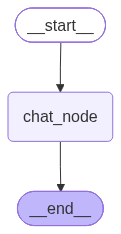

In [14]:
chatbot

In [15]:
initial_state = {
    'messages': [HumanMessage(content='What is the capital of india')]
}

chatbot.invoke(initial_state)['messages'][-1].content

'The capital of India is New Delhi.'